# 📘 MAKİNE ÖĞRENMESİ — ÜNİTE 5 LAB
## Çok Değişkenli Yöntemler | 120 dakika | **Öğretmen sürümü (çözümlü)**

**Teori eşleştirmesi:** Alpaydın (2014), *Introduction to Machine Learning*, 5.1–5.8. Teorik ders slaytlarındaki örneklerin bir kısmı **aynı sayılarla** tekrar çözülür. Kaynaktaki **Şekil 5.1–5.7** doğrudan notebook içine gömülmüştür; bu nedenle internet olmadan da görünür.

**Hedef kitle:** Python ve makine öğrenmesine yeni başlayanlar. Her adımda önce "ne yapmak istiyoruz?", sonra "hangi hesaplama?", sonra "Python karşılığı?" ilerleriz.

**Gereksinimler:** Çekirdek hesaplamalarda yalnızca **Python standart kütüphanesi** (`math`, `statistics`) gerekir. Grafikler için **isteğe bağlı `matplotlib`** kullanılır. `numpy`, `pandas` veya `scikit-learn` zorunlu değildir.

> **Öğretmen notu:** 💡 *Anlat* bölümleri konuşma rehberi, ✏️ *Öğrenci denemesi* bölümleri sınıfa yöneltilecek sorulardır. Cevaplar hemen sonrasındaki **✅ Öğretmen çözümü** hücrelerindedir. Öğrencilerden önce tahmin isteyin, sonra ilgili çözüm hücresini çalıştırın.

### Ders akışı (toplam 120 dakika)

| Süre | Konu | Teori | Uygulama |
|---:|---|---|---|
| 0–5 dk | Başlangıç ve Python hatırlatma | Genel | Değişken, liste, `for` |
| 5–25 dk | Veri matrisi, ortalama, varyans, kovaryans | 5.1–5.2 | Matris, korelasyon, örnek hesap |
| 25–35 dk | Eksik veriler | 5.3 | Ortalama ile doldurma, veri sızıntısı |
| 35–55 dk | Normal dağılım ve Mahalanobis | 5.4 | Yoğunluk, uzaklık, kovaryans şekilleri |
| 55–80 dk | Çok değişkenli sınıflandırma | 5.5 | QDA, LDA, önsel olasılık, grafikler |
| 80–90 dk | Karmaşıklık ve RDA | 5.6 | Parametre sayısı, kovaryans karışımı |
| 90–105 dk | Ayrık özellikler ve Naive Bayes | 5.7 | Spam sınıflandırma, one-hot |
| 105–120 dk | Çoklu doğrusal regresyon | 5.8 | Normal denklem, 3×3 çözüm, MSE |

**Ders kazanımları:** Öğrenci bir özellik matrisi hazırlayabilir; ortalama/kovaryans hesaplayabilir; eksik değerleri eğitim verisinden öğrendiği istatistiklerle doldurabilir; Mahalanobis uzaklığını yorumlar; QDA/LDA farkını görür; Naive Bayes ile olasılık hesabı ve çoklu regresyonla tahmin yapar.

---
# 0. Derse başlangıç — 5 dakika

**💡 Anlat:** "Bir kişinin yaşı, geliri, çalışma saati gibi birden fazla bilgisi varsa bunları bir satırda tutabiliriz. Python'da bunun en basit karşılığı liste içindeki listedir."

Kod hücresini çalıştırmak için `Shift + Enter` kullanın. Kodun yanındaki `#` açıklama satırıdır ve çalıştırılmaz.

In [1]:
# Basit Python hatırlatma: liste, döngü, toplam, uzunluk
notlar = [70, 80, 90]
print("Notlar:", notlar)
print("Öğrenci sayısı:", len(notlar))
print("Not toplamı:", sum(notlar))
print("Ortalama:", sum(notlar) / len(notlar))

for sira, not_degeri in enumerate(notlar, start=1):
    print(f"{sira}. öğrencinin notu = {not_degeri}")

Notlar: [70, 80, 90]
Öğrenci sayısı: 3
Not toplamı: 240
Ortalama: 80.0
1. öğrencinin notu = 70
2. öğrencinin notu = 80
3. öğrencinin notu = 90


### ✏️ Öğrenci denemesi (30–60 saniye)

`[60, 70, 80, 90]` notlarının ortalaması kaçtır? Önce kağıtta bulun, sonra aşağıdaki kodu çalıştırın.

In [2]:
# ✅ Öğretmen çözümü
ogrenci_notlari = [60, 70, 80, 90]
ortalama = sum(ogrenci_notlari) / len(ogrenci_notlari)
print("Ortalama =", ortalama)  # Beklenen: 75.0

Ortalama = 75.0


---
# 1. Çok değişkenli veri ve temel istatistik — 20 dakika
## 1.1 Veri matrisi (5.1)

**💡 Anlat:** Bir satır **bir öğrenci**, bir sütun **bir özellik (feature)** demektir. **N:** satır sayısı, **d:** sütun sayısı. Veriyi `X` ile göstereceğiz.

| Öğrenci | Çalışma saati | Devam (%) | Önceki not |
|---|---:|---:|---:|
| 1 | 2 | 60 | 50 |
| 2 | 4 | 75 | 65 |
| 3 | 6 | 90 | 80 |
| 4 | 8 | 95 | 90 |

\[
X = \begin{bmatrix} 2&60&50\\ 4&75&65\\ 6&90&80\\ 8&95&90\end{bmatrix}
\qquad X\in\mathbb{R}^{4\times3}
\]

In [3]:
# Satır = gözlem; sütun = özellik
X = [
    [2, 60, 50],
    [4, 75, 65],
    [6, 90, 80],
    [8, 95, 90],
]
N = len(X)       # Gözlem sayısı
D = len(X[0])    # Özellik sayısı
print(f"Veri matrisi: {N} satır × {D} sütun")
print("1. öğrenci:", X[0])
print("3. öğrencinin önceki notu:", X[2][2])
print("Bütün öğrencilerin çalışma saatleri:", [satir[0] for satir in X])

Veri matrisi: 4 satır × 3 sütun
1. öğrenci: [2, 60, 50]
3. öğrencinin önceki notu: 80
Bütün öğrencilerin çalışma saatleri: [2, 4, 6, 8]


## 1.2 Ortalama vektörü (5.2)

Her sütunun ortalamasını ayrı hesaplarız:

\[
\mu_j=\frac{1}{N}\sum_{t=1}^{N}x_j^{(t)}
\]

**Önemli:** `X[0]` bir satırdır; `[satir[0] for satir in X]` birinci sütundur.

In [4]:
# Önce tek bir sütunun ortalamasını bulalım.
calisma_saatleri = [satir[0] for satir in X]
ortalama_calisma = sum(calisma_saatleri) / len(calisma_saatleri)
print("Çalışma saatleri:", calisma_saatleri)
print("Çalışma saati ortalaması:", ortalama_calisma)

# Şimdi bütün sütunlar için hesaplayalım.
ortalama_vektoru = []
for sutun in range(D):
    degerler = [satir[sutun] for satir in X]
    ort = sum(degerler) / N
    ortalama_vektoru.append(ort)
    print(f"Özellik {sutun+1}: toplam={sum(degerler)}, ortalama={ort:.2f}")
print("Ortalama vektörü:", ortalama_vektoru)

Çalışma saatleri: [2, 4, 6, 8]
Çalışma saati ortalaması: 5.0
Özellik 1: toplam=20, ortalama=5.00
Özellik 2: toplam=320, ortalama=80.00
Özellik 3: toplam=285, ortalama=71.25
Ortalama vektörü: [5.0, 80.0, 71.25]


## 1.3 Varyans: Tek değişken ne kadar yayılıyor?

\[
\operatorname{Var}(X)=\frac1N\sum_{t=1}^N(x^{(t)}-\bar x)^2
\]

**Aşamalar:** (1) Ortalama, (2) her değerden ortalamayı çıkar, (3) farkın karesini al, (4) topla, (5) `N`'e böl. Burada kitapla uyum için **maksimum olabilirlik (MLE) varyansı** kullanılır; klasik örneklem düzeltmesinde `N-1` kullanıldığını hatırlatın.

In [5]:
# Mini örnek: X1 = [1,2,3], X2 = [2,4,3]
x1 = [1, 2, 3]
x2 = [2, 4, 3]
n = len(x1)
m1 = sum(x1)/n
m2 = sum(x2)/n
print("Ortalamalar:", m1, m2)

fark1 = [deger - m1 for deger in x1]
fark2 = [deger - m2 for deger in x2]
print("X1 ortalama farkları:", fark1)
print("X2 ortalama farkları:", fark2)

var1 = sum(fark**2 for fark in fark1)/n
var2 = sum(fark**2 for fark in fark2)/n
print(f"Var(X1) = {var1:.4f} = 2/3")
print(f"Var(X2) = {var2:.4f} = 2/3")

Ortalamalar: 2.0 3.0
X1 ortalama farkları: [-1.0, 0.0, 1.0]
X2 ortalama farkları: [-1.0, 1.0, 0.0]
Var(X1) = 0.6667 = 2/3
Var(X2) = 0.6667 = 2/3


## 1.4 Kovaryans ve korelasyon

**Kovaryans:** İki değişken aynı anda nasıl değişiyor?

\[
\operatorname{Cov}(X_1,X_2)=\frac1N\sum_{t=1}^N(x_1^{(t)}-m_1)(x_2^{(t)}-m_2)
\]

**Korelasyon:** Kovaryansın `[-1, 1]` aralığına standartlaştırılmış hâli.

\[
\rho=\frac{\operatorname{Cov}(X_1,X_2)}{\sigma_1\sigma_2}
\]

| İşaret | Yorum |
|---|---|
| Pozitif | Biri artarken diğeri de artma eğiliminde |
| Negatif | Biri artarken diğeri azalma eğiliminde |
| Sıfır | Doğrusal birlikte değişim yok; **bağımsızlık garanti değil** |

In [6]:
# Önce ara çarpımları tek tek görelim.
carpimlar = []
for a, b in zip(fark1, fark2):
    carpim = a*b
    carpimlar.append(carpim)
    print(f"{a:>3} × {b:>3} = {carpim:>3}")
kovaryans = sum(carpimlar) / n
korelasyon = kovaryans / (var1**0.5 * var2**0.5)
print(f"Kovaryans = ({' + '.join(str(i) for i in carpimlar)})/{n} = {kovaryans:.4f}")
print(f"Korelasyon = {korelasyon:.4f}  (beklenen 0.5)")

-1.0 × -1.0 = 1.0
0.0 × 1.0 = 0.0
1.0 × 0.0 = 0.0
Kovaryans = (1.0 + 0.0 + 0.0)/3 = 0.3333
Korelasyon = 0.5000  (beklenen 0.5)


## 1.5 Kovaryans matrisi

İki özellik için:

\[
S =\begin{bmatrix}
\operatorname{Var}(X_1)&\operatorname{Cov}(X_1,X_2)\\
\operatorname{Cov}(X_2,X_1)&\operatorname{Var}(X_2)
\end{bmatrix}
\]

Bir sonraki fonksiyon her boyutta kullanılabilir. Formülde `N`'e bölme işlemini özellikle görünür bıraktık.

In [7]:
def sutun_ortalamalari(veri):
    """N x d veri matrisinin her sütununun ortalaması."""
    n = len(veri)
    d = len(veri[0])
    return [sum(satir[j] for satir in veri)/n for j in range(d)]


def kovaryans_matrisi(veri):
    """MLE kovaryans matrisi: her çapraz çarpımın toplamı / N."""
    n = len(veri)
    d = len(veri[0])
    ort = sutun_ortalamalari(veri)
    sonuc = []
    for i in range(d):
        satir_sonuc = []
        for j in range(d):
            toplam = sum((satir[i]-ort[i])*(satir[j]-ort[j]) for satir in veri)
            satir_sonuc.append(toplam/n)
        sonuc.append(satir_sonuc)
    return sonuc

S = kovaryans_matrisi([[1,2], [2,4], [3,3]])
for satir in S:
    print([round(sayi,4) for sayi in satir])
print("Diyagonal: varyanslar | Diğer elemanlar: kovaryans")

[0.6667, 0.3333]
[0.3333, 0.6667]
Diyagonal: varyanslar | Diğer elemanlar: kovaryans


### ✏️ Öğrenci denemesi: Negatif kovaryans

`a = [1,2,3]`, `b = [3,2,1]` için ortalamaları ve kovaryansı önce hesap makinesiyle bulun. **Beklenen:** `Cov(a,b) = -2/3`, `Corr(a,b)=-1`.

In [8]:
# ✅ Öğretmen çözümü
veri_negatif = [[1,3], [2,2], [3,1]]
S_neg = kovaryans_matrisi(veri_negatif)
corr_neg = S_neg[0][1] / ((S_neg[0][0]*S_neg[1][1])**0.5)
print("Kovaryans matrisi:", S_neg)
print("Kovaryans =", round(S_neg[0][1],4))
print("Korelasyon =", round(corr_neg,4))
assert abs(corr_neg + 1) < 1e-10

Kovaryans matrisi: [[0.6666666666666666, -0.6666666666666666], [-0.6666666666666666, 0.6666666666666666]]
Kovaryans = -0.6667
Korelasyon = -1.0


---
# 2. Eksik değer tamamlama — 10 dakika (5.3)

**💡 Anlat:** Veri eksikse her zaman satırı silmek zorunda değiliz. Sayısal sütun için **ortalama**, kategorik sütun için **en sık görülen değer** kullanılabilir; ilişkiler güçlü ise regresyonla tahmin düşünülebilir.

`None`, Python'da eksik değeri temsil edebilir. `sum()` fonksiyonu `None` içeren liste üzerinde doğrudan çalışmaz.

In [9]:
notlar = [70, 80, None, 90]
mevcut_notlar = [puan for puan in notlar if puan is not None]
ort = sum(mevcut_notlar) / len(mevcut_notlar)
doldurulmus = [ort if puan is None else puan for puan in notlar]
print("Önce:", notlar)
print("Mevcut not ortalaması:", ort)
print("Sonra:", doldurulmus)

Önce: [70, 80, None, 90]
Mevcut not ortalaması: 80.0
Sonra: [70, 80, 80.0, 90]


## 2.1 Ortalama yerine regresyonla doldurmak

Teori örneğinde `not = 10 × çalışma_süresi + 30` ilişkisi olsun. Öğrenci 6 saat çalıştıysa:

\[
\hat y=10\times6+30=90
\]

Diğer notların ortalaması `(50+70+110)/3 = 76.67` iken regresyon önerisi **90**'dır. Bu örnekte formül eğitim verisinden öğrenilmiş kabul edilir.

In [10]:
bilinen_notlar = [50, 70, 110]
ortalama_tahmin = sum(bilinen_notlar) / len(bilinen_notlar)
regresyon_tahmin = 10 * 6 + 30
print(f"Ortalama ile doldurma: {ortalama_tahmin:.2f}")
print(f"Regresyon ile doldurma: {regresyon_tahmin:.2f}")

Ortalama ile doldurma: 76.67
Regresyon ile doldurma: 90.00


## 2.2 Veri sızıntısı (data leakage) — mutlaka anlat

Örneğin eğitim kümesi `[70, 80, 90]`, test kümesi `[None, 100]` olsun. Test kümesinin bilinen `100` değerini dahil ederek eğitim ortalamasını hesaplamak **hatalıdır**. Ön işleme istatistiği yalnızca eğitimden öğrenilir ve **değişmeden** testte uygulanır.

In [11]:
train_notlar = [70, 80, 90]
test_notlar = [None, 100]
train_ortalama = sum(train_notlar)/len(train_notlar)  # SADECE EĞİTİM!
test_tamam = [train_ortalama if x is None else x for x in test_notlar]
print("Eğitim ortalaması:", train_ortalama)
print("Test kümesinin doğru biçimde doldurulmuş hâli:", test_tamam)
print("Uyarı: testteki 100, eğitim ortalamasını hesaplarken kullanılmadı.")

Eğitim ortalaması: 80.0
Test kümesinin doğru biçimde doldurulmuş hâli: [80.0, 100]
Uyarı: testteki 100, eğitim ortalamasını hesaplarken kullanılmadı.


### ✏️ Öğrenci denemesi

Eğitim notları `[50,70,90]`, test notları `[None,80]` için doldurulan ilk test değerini bulun. Neden `80` test değerini ortalamaya dahil etmiyoruz?

In [12]:
# ✅ Öğretmen çözümü
train = [50,70,90]
test = [None,80]
train_mean = sum(train)/len(train)
sonuc = [train_mean if x is None else x for x in test]
print(sonuc)  # [70.0,80]; çünkü test bilgisi eğitime karışmamalı

[70.0, 80]


---
# 3. Çok değişkenli normal dağılım — 20 dakika (5.4)

**💡 Anlat:** Ortalamaları ve kovaryansları öğrendiğimize göre artık iki özellikli bir veri grubunu bir olasılık dağılımıyla modelleyebiliriz. Merkez `μ`, yayılım/yön `Σ` ile tanımlanır.

\[
p(x)=\frac{\exp\left[-\frac12(x-\mu)^T\Sigma^{-1}(x-\mu)\right]}
{(2\pi)^{d/2}|\Sigma|^{1/2}}
\]

**Olasılık yoğunluğu** ile **tek bir noktanın olasılığını** karıştırmayın: Sürekli dağılımda tam bir noktanın olasılığı sıfırdır. Yoğunluk belirli bir bölgenin olasılığını hesaplamak için kullanılır.

### Şekil 5.1 — İki değişkenli normal dağılım

![İki değişkenli normal dağılım](attachment:figure_Şekil 5_1.png)

**Grafik yorumu:** 3B yüzeyin yatay eksenleri `x₁` ve `x₂`, dikey ekseni `p(x₁,x₂)` yoğunluğudur. Tepe merkez çevresinde oluşur; merkezden uzaklaşınca yoğunluk azalır.

*Görsel: kullanıcı tarafından sağlanan Alpaydın (2014) kaynak şekli; açıklamalar eğitim amaçlıdır.*
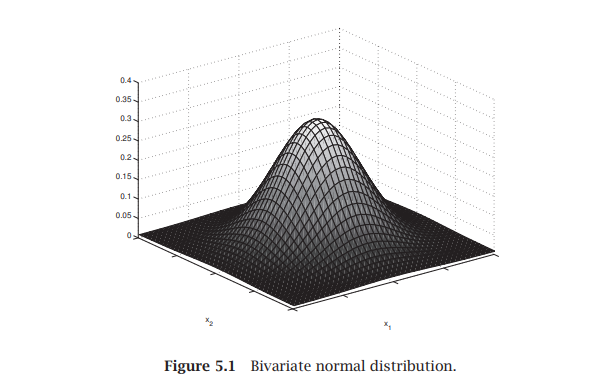

### Şekil 5.2 — Kovaryans matrisi ve eş yoğunluk konturları

![Kovaryans matrisi ve eş yoğunluk konturları](attachment:figure_Şekil 5_2.png)

**Grafik yorumu:** Kovaryans sıfır ve varyanslar eşitse **daire**; varyanslar farklıysa **eksenlere paralel elips**; pozitif kovaryansta elips yukarı eğimli, negatif kovaryansta aşağı eğimlidir.

*Görsel: kullanıcı tarafından sağlanan Alpaydın (2014) kaynak şekli; açıklamalar eğitim amaçlıdır.*
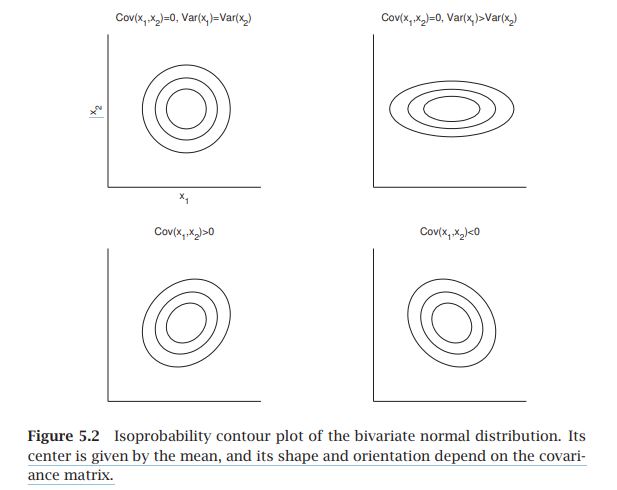

## 3.1 Öklid ve Mahalanobis uzaklıkları

- **Öklid:** Noktalar arasındaki ham geometrik uzaklık.
- **Mahalanobis:** Her değişkenin varyansını ve değişkenler arasındaki ilişkiyi dikkate alan uzaklık.

\[
D_E(x,\mu)=\sqrt{\sum_j(x_j-\mu_j)^2}
\]

\[
D_M(x,\mu)=\sqrt{(x-\mu)^T\Sigma^{-1}(x-\mu)}
\]

**Teoriyle aynı örnek:** `μ=[0,0]`, `Σ=diag(1,9)`, `x=[1,3]`.

\[
D_E=\sqrt{1^2+3^2}=\sqrt{10}\approx3.16
\]

\[
D_M=\sqrt{1^2/1+3^2/9}=\sqrt2\approx1.41
\]

In [13]:
import math

mu = [0, 0]
x = [1, 3]
variances = [1, 9]  # Σ köşegen: [1,9], çapraz kovaryans sıfır
farklar = [x[j] - mu[j] for j in range(2)]

oklid_kare = sum(fark**2 for fark in farklar)
mahal_kare = sum(farklar[j]**2 / variances[j] for j in range(2))

print("Ortalamadan farklar:", farklar)
print("Öklid² = 1²+3² =", oklid_kare)
print("Mahalanobis² = 1²/1 + 3²/9 =", mahal_kare)
print(f"Öklid = {math.sqrt(oklid_kare):.4f}")
print(f"Mahalanobis = {math.sqrt(mahal_kare):.4f}")

Ortalamadan farklar: [1, 3]
Öklid² = 1²+3² = 10
Mahalanobis² = 1²/1 + 3²/9 = 2.0
Öklid = 3.1623
Mahalanobis = 1.4142


## 3.2 İki boyutlu matrisin determinantı ve tersi

Genel kovaryans için çapraz terimleri de hesaba katmamız gerekir:

\[
\Sigma=\begin{bmatrix}a&b\\c&d\end{bmatrix},\qquad
|\Sigma|=ad-bc
\]

\[
\Sigma^{-1}=\frac1{ad-bc}\begin{bmatrix}d&-b\\-c&a\end{bmatrix}
\]

Matrisin determinantı sıfırsa normal ters matris yoktur. Aşağıdaki fonksiyonlar **yalnızca 2×2** için yazılmıştır; amaç hesaplamayı şeffaf kılmaktır.

In [14]:
def det_2x2(A):
    return A[0][0]*A[1][1] - A[0][1]*A[1][0]


def ters_2x2(A):
    determinant = det_2x2(A)
    if determinant <= 1e-12:
        raise ValueError("Kovaryans matrisi pozitif tanımlı/terslenebilir olmalı.")
    a,b = A[0]
    c,d = A[1]
    return [[d/determinant, -b/determinant],
            [-c/determinant, a/determinant]]


def matris_vektor_2x2(A, x):
    return [A[0][0]*x[0]+A[0][1]*x[1],
            A[1][0]*x[0]+A[1][1]*x[1]]


def noktasal_carpim(a,b):
    return sum(u*v for u,v in zip(a,b))

kov = [[4,2],[2,4]]
print("Σ =", kov)
print("Determinant =", det_2x2(kov), "(16 - 4 = 12)")
print("Σ^-1 =", ters_2x2(kov))

Σ = [[4, 2], [2, 4]]
Determinant = 12 (16 - 4 = 12)
Σ^-1 = [[0.3333333333333333, -0.16666666666666666], [-0.16666666666666666, 0.3333333333333333]]


## 3.3 Genel Mahalanobis uzaklığını elle kodlayalım

Her matris adımı görünür: `fark → ters kovaryans × fark → iç çarpım → karekök`.

In [15]:
def mahalanobis_2d(x, mu, Sigma):
    fark = [x[i]-mu[i] for i in range(2)]
    ters = ters_2x2(Sigma)
    carpim = matris_vektor_2x2(ters, fark)
    kare = noktasal_carpim(fark, carpim)
    return math.sqrt(max(0, kare))

print("Örnek 1 — Çapraz kovaryans sıfır:")
print(mahalanobis_2d([1,3], [0,0], [[1,0],[0,9]]))
print("Örnek 2 — Pozitif kovaryans var:")
print(mahalanobis_2d([1,3], [0,0], [[1,0.5],[0.5,9]]))

Örnek 1 — Çapraz kovaryans sıfır:
1.4142135623730951
Örnek 2 — Pozitif kovaryans var:
1.3093073414159542


## 3.4 Olasılık yoğunluğunu kodlayalım

Birazdan LDA ve QDA'da da kullanacağımız iki boyutlu Gaussian **log-yoğunluğu**:

\[
\log p(x\mid C_i)=-\log(2\pi)-\tfrac12\log|\Sigma_i|-\tfrac12D_M^2(x,\mu_i)
\]

`log`, doğal logaritmadır. Doğrudan yoğunluk yerine log-yoğunluk hesaplamak, çok küçük değerler için daha kararlıdır.

In [16]:
def log_normal_2d(x, mu, Sigma):
    determinant = det_2x2(Sigma)
    if determinant <= 0:
        raise ValueError("Determinant pozitif olmalıdır.")
    uzaklik = mahalanobis_2d(x, mu, Sigma)
    return -math.log(2*math.pi) - 0.5*math.log(determinant) - 0.5*uzaklik**2

mu0 = [0,0]
Sigma0 = [[1,0],[0,1]]
for nokta in [[0,0],[1,0],[1,1],[2,2]]:
    log_yogunluk = log_normal_2d(nokta, mu0, Sigma0)
    print(f"x={nokta}, p(x)={math.exp(log_yogunluk):.5f}")

x=[0, 0], p(x)=0.15915
x=[1, 0], p(x)=0.09653
x=[1, 1], p(x)=0.05855
x=[2, 2], p(x)=0.00292


### ✏️ Öğrenci denemesi: Kovaryansın etkisini tahmin et

`x=[0,2]` için önce `Σ=diag(1,1)`, sonra `Σ=diag(1,9)` kullanın. İkinci durumda Mahalanobis uzaklığı neden daha küçüktür?

In [17]:
# ✅ Öğretmen çözümü
nokta = [0,2]
kucuk_varyans = mahalanobis_2d(nokta,[0,0],[[1,0],[0,1]])
buyuk_varyans = mahalanobis_2d(nokta,[0,0],[[1,0],[0,9]])
print(f"İkinci boyut varyansı 1 ise: {kucuk_varyans:.4f}")
print(f"İkinci boyut varyansı 9 ise: {buyuk_varyans:.4f}")
print("Yorum: çok değişken olan yönde aynı ham fark daha az sıra dışıdır.")

İkinci boyut varyansı 1 ise: 2.0000
İkinci boyut varyansı 9 ise: 0.6667
Yorum: çok değişken olan yönde aynı ham fark daha az sıra dışıdır.


## 3.5 İsteğe bağlı grafik: Dört kovaryans senaryosu

Grafik hücresi `matplotlib` kuruluysa çalışır; kurulu değilse dersin **hesaplama kısmı yine çalışır**. Birinci ve ikinci değişkenlerin normal yoğunluğunu farklı kovaryanslarla çizerek Şekil 5.2'yi yeniden üretiriz.

In [18]:
# Grafik için tek isteğe bağlı dış paket: matplotlib
try:
    import matplotlib.pyplot as plt
    GRAFIK_VAR = True
    print("Grafik desteği hazır: matplotlib")
except ImportError:
    GRAFIK_VAR = False
    print("matplotlib yok: Grafik atlandı, bütün hesaplamalar çalışmaya devam edecek.")

Grafik desteği hazır: matplotlib


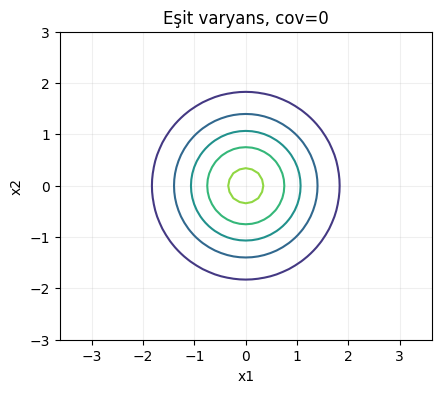

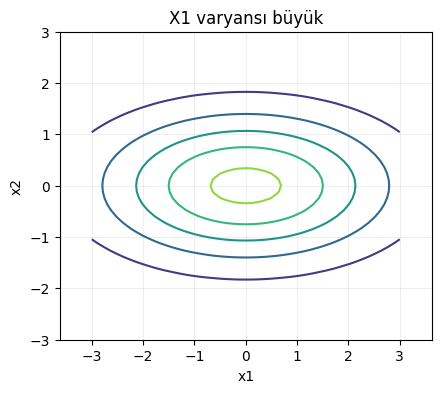

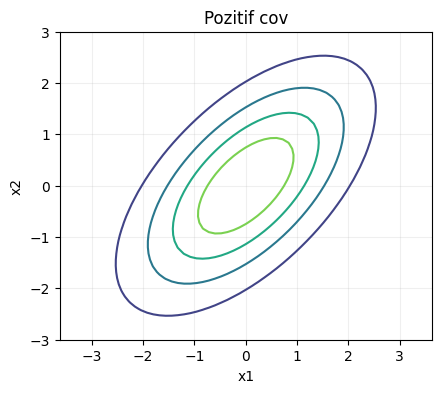

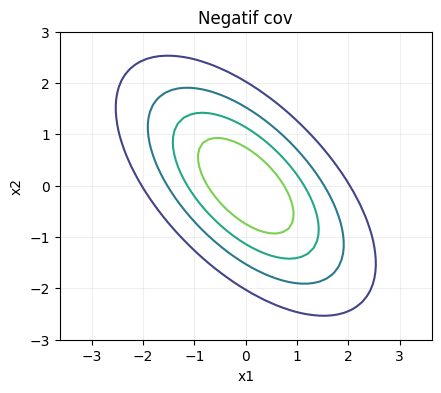

In [19]:
# Şekil 5.2'nin matematiksel karşılığı — dört farklı kovaryans
# Z matrisini listelerle hazırlıyoruz (numpy yazmak gerekmiyor).
senaryolar = [
    ("Eşit varyans, cov=0", [[1,0],[0,1]]),
    ("X1 varyansı büyük", [[4,0],[0,1]]),
    ("Pozitif cov", [[2,1.2],[1.2,2]]),
    ("Negatif cov", [[2,-1.2],[-1.2,2]]),
]
if GRAFIK_VAR:
    xs = [-3 + 0.12*i for i in range(51)]
    ys = [-3 + 0.12*i for i in range(51)]
    for baslik, Sigma_s in senaryolar:
        z = [[math.exp(log_normal_2d([a,b],[0,0],Sigma_s)) for a in xs] for b in ys]
        plt.figure(figsize=(4.8,4.0))
        plt.contour(xs,ys,z,levels=5)
        plt.xlabel("x1"); plt.ylabel("x2")
        plt.title(baslik)
        plt.axis("equal"); plt.grid(alpha=0.2)
        plt.show()
else:
    print("Grafik hücresi geçildi.")

---
# 4. Çok değişkenli sınıflandırma — 25 dakika (5.5)

**💡 Anlat:** Bir sınıfın bir "merkezi" ve bir "yayılım şekli" vardır. Yeni `x` noktasının her sınıf altında ne kadar olası olduğunu karşılaştırırız. Karar skoruna **ayırt edici fonksiyon** denir.

\[
g_i(x)=\log p(x\mid C_i)+\log P(C_i)
\]

**`P(Cᵢ)` önsel olasılık**: Gözlemin özelliklerini görmeden önce sınıfın görülme sıklığı / önsel bilgimiz.

**`p(x|Cᵢ)` koşullu yoğunluk**: Gözlem, ilgili sınıfın dağılımında ne kadar yoğun bölgede?

**`P(Cᵢ|x)` sonsal olasılık**: Gözlemi gördükten sonra sınıfa atadığımız olasılık.

### Şekil 5.3 — Farklı kovaryanslarla QDA ve eğrisel sınır

![Farklı kovaryanslarla QDA ve eğrisel sınır](attachment:figure_Şekil 5_3.png)

**Grafik yorumu:** İki sınıfın yayılımları farklı olabilir. Üstte koşullu yoğunluk ve sonsal olasılık, altta eş yoğunluk elipsleri ve **eğrisel** karar sınırı görülür. Genel kural: Farklı kovaryans → **QDA**.

*Görsel: kullanıcı tarafından sağlanan Alpaydın (2014) kaynak şekli; açıklamalar eğitim amaçlıdır.*
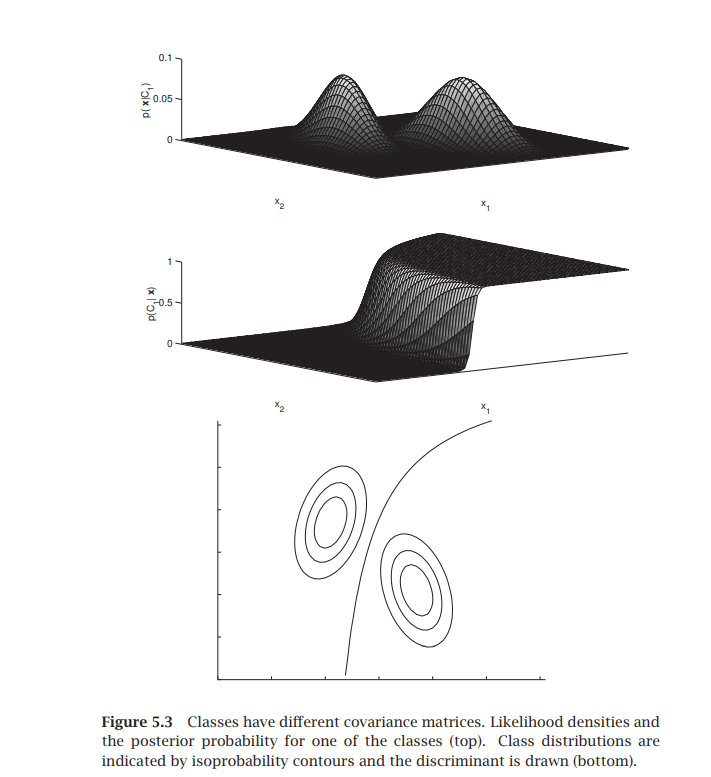

## 4.1 Önsel olasılığı eğitim verisinden öğrenmek

Her sınıfın örnek sayısını toplam örnek sayısına bölüyoruz: `P(Cᵢ) = Nᵢ/N`.

In [20]:
etiketler = ["Ekonomik", "Ekonomik", "Ekonomik", "Lüks", "Lüks", "Lüks"]
for sinif in sorted(set(etiketler)):
    n_sinif = etiketler.count(sinif)
    prior = n_sinif / len(etiketler)
    print(f"P({sinif}) = {n_sinif}/{len(etiketler)} = {prior:.2f}")

P(Ekonomik) = 3/6 = 0.50
P(Lüks) = 3/6 = 0.50


## 4.2 QDA: Her sınıfın kovaryansı farklı

Eğitimde her sınıfın ortalamasını ve kovaryansını ayrı buluruz. **Küçük örneklem uyarısı:** Her sınıftaki noktalar tek bir doğru üzerindeyse kovaryans terslenemez. Bu yüzden aşağıdaki örneği *doğrusal bağımsız* iki boyutlu küçük dağılımlarla hazırladık.

In [21]:
# Örnek veriler: Her gözlem [x1, x2]
C1_veri = [[0.6,2.5], [0.9,3.1], [1.1,3.6], [1.3,2.8], [1.6,3.0]]
C2_veri = [[2.2,1.0], [2.8,1.7], [3.0,0.6], [3.5,1.1], [3.8,1.9]]

m_C1 = sutun_ortalamalari(C1_veri)
m_C2 = sutun_ortalamalari(C2_veri)
S_C1 = kovaryans_matrisi(C1_veri)
S_C2 = kovaryans_matrisi(C2_veri)

print("Sınıf 1 ortalaması:", m_C1)
print("Sınıf 2 ortalaması:", m_C2)
print("Sınıf 1 kovaryansı:", [[round(v,3) for v in row] for row in S_C1])
print("Sınıf 2 kovaryansı:", [[round(v,3) for v in row] for row in S_C2])
print("Determinantlar:", round(det_2x2(S_C1),5), round(det_2x2(S_C2),5))

Sınıf 1 ortalaması: [1.1, 3.0]
Sınıf 2 ortalaması: [3.06, 1.26]
Sınıf 1 kovaryansı: [[0.116, 0.038], [0.038, 0.132]]
Sınıf 2 kovaryansı: [[0.31, 0.11], [0.11, 0.226]]
Determinantlar: 0.01387 0.05809


In [22]:
def sinif_skoru(x, mu, Sigma, prior):
    """Gaussian log-yoğunluğu + önsel log-olasılığı."""
    return log_normal_2d(x,mu,Sigma) + math.log(prior)


def qda_tahmin(x, prior1=0.5, prior2=0.5):
    skor1 = sinif_skoru(x, m_C1, S_C1, prior1)
    skor2 = sinif_skoru(x, m_C2, S_C2, prior2)
    return ("C1" if skor1>skor2 else "C2"), skor1, skor2

for nokta in [[1.0,3.0],[3.0,1.0],[2.0,2.0]]:
    sinif, s1, s2 = qda_tahmin(nokta)
    print(f"x={nokta}, g1={s1:.3f}, g2={s2:.3f} => {sinif}")

x=[1.0, 3.0], g1=-0.440, g2=-24.280 => C1
x=[3.0, 1.0], g1=-44.714, g2=-1.266 => C2
x=[2.0, 2.0], g1=-10.895, g2=-6.252 => C2


## 4.3 LDA: Bütün sınıflarda ortak kovaryans

\[
S=\sum_iP(C_i)S_i
\]

İki eş büyüklüklü sınıf için bu, iki kovaryans matrisinin ortalamasıdır. **Ortak kovaryans, karar sınırını doğrusal yapar.**

### Şekil 5.4 — Ortak kovaryans ve doğrusal sınır

![Ortak kovaryans ve doğrusal sınır](attachment:figure_Şekil 5_4.png)

**Grafik yorumu:** Elipslerin yönü ve boyutları aynıdır çünkü sınıflar **aynı S** matrisini paylaşır. İki sınıf arasında çizilen sınır doğrudur (LDA).

*Görsel: kullanıcı tarafından sağlanan Alpaydın (2014) kaynak şekli; açıklamalar eğitim amaçlıdır.*
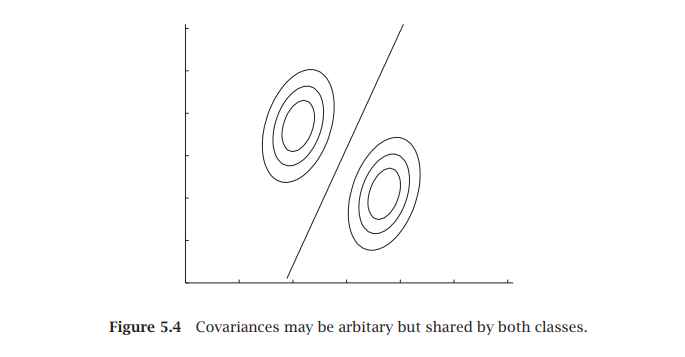

In [23]:
# Her iki sınıfta da 5 örnek olduğu için ortak kovaryans = 0.5*S1 + 0.5*S2
S_ortak = [[0.5*S_C1[i][j]+0.5*S_C2[i][j] for j in range(2)] for i in range(2)]
print("Ortak kovaryans:", [[round(v,3) for v in row] for row in S_ortak])


def lda_tahmin(x, prior1=0.5, prior2=0.5):
    skor1 = sinif_skoru(x,m_C1,S_ortak,prior1)
    skor2 = sinif_skoru(x,m_C2,S_ortak,prior2)
    return ("C1" if skor1>skor2 else "C2"), skor1, skor2

for nokta in [[1.0,3.0],[3.0,1.0],[2.0,2.0]]:
    sinif, s1, s2 = lda_tahmin(nokta)
    print(f"x={nokta}, g1={s1:.3f}, g2={s2:.3f} => {sinif}")

Ortak kovaryans: [[0.213, 0.074], [0.074, 0.179]]
x=[1.0, 3.0], g1=-0.848, g2=-30.452 => C1
x=[3.0, 1.0], g1=-32.375, g2=-1.016 => C2
x=[2.0, 2.0], g1=-8.342, g2=-7.465 => C2


## 4.4 Önsel olasılık kararı nasıl değiştirebilir?

**Teorik slayttaki örnekle aynı sayılar:**

\[
m_1=(1,3),\quad m_2=(3,1),\quad S=I,\quad x=(1.5,2.5)
\]

Önce Mahalanobis uzaklık kareleri: `D1²=0.5`, `D2²=4.5`. Eşit önsellerde **C1** seçilir; ancak önselleri 0.1 / 0.9 yaparsak sonuç **C2** olabilir.

In [24]:
ornek_nokta = [1.5,2.5]
m1_ = [1,3]
m2_ = [3,1]
I = [[1,0],[0,1]]

for prior1, prior2 in [(0.5,0.5),(0.1,0.9)]:
    skor1=sinif_skoru(ornek_nokta,m1_,I,prior1)
    skor2=sinif_skoru(ornek_nokta,m2_,I,prior2)
    kazanan = "C1" if skor1>skor2 else "C2"
    print(f"P(C1)={prior1}, P(C2)={prior2} | g1={skor1:.3f}, g2={skor2:.3f} => {kazanan}")
print("Kontrol: eşit önselde C1, 0.1/0.9 önselde C2 bekleniyor.")

P(C1)=0.5, P(C2)=0.5 | g1=-2.781, g2=-4.781 => C1
P(C1)=0.1, P(C2)=0.9 | g1=-4.390, g2=-4.193 => C2
Kontrol: eşit önselde C1, 0.1/0.9 önselde C2 bekleniyor.


## 4.5 Köşegen ve küresel kovaryans

İki daha basit model:

- **Köşegen ortak kovaryans:** `S=[[σ₁²,0],[0,σ₂²]]`. Değişkenler sınıf içinde bağımsız; elipslerin eksenleri yatay/dikey.
- **Küresel ortak kovaryans:** `S=s² I`. Varyanslar da eşit; eş yoğunluk çizgileri daire. Önsel olasılıklar eşitse **en yakın ortalama** karar verir.

### Şekil 5.5 — Köşegen ortak kovaryans

![Köşegen ortak kovaryans](attachment:figure_Şekil 5_5.png)

**Grafik yorumu:** Kovaryans sıfır; dikey yönde varyans daha büyük olduğu için elipsler dikey. Ortak matris yüzünden karar sınırı doğrusal.

*Görsel: kullanıcı tarafından sağlanan Alpaydın (2014) kaynak şekli; açıklamalar eğitim amaçlıdır.*
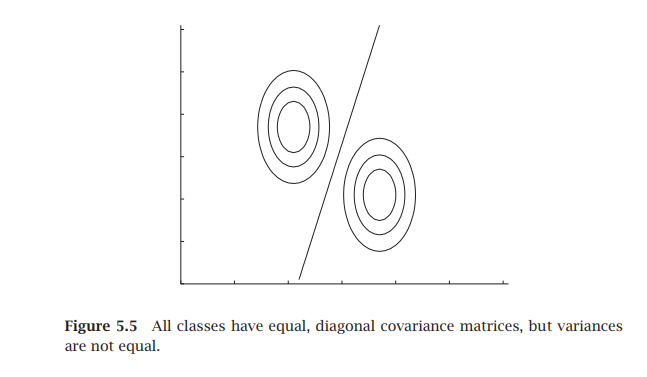

### Şekil 5.6 — Küresel ortak kovaryans

![Küresel ortak kovaryans](attachment:figure_Şekil 5_6.png)

**Grafik yorumu:** Her iki boyutta varyans eşit; konturlar **daire**. Önsel olasılıklar eşitse yeni nokta yakın olduğu ortalamanın sınıfına atanır.

*Görsel: kullanıcı tarafından sağlanan Alpaydın (2014) kaynak şekli; açıklamalar eğitim amaçlıdır.*
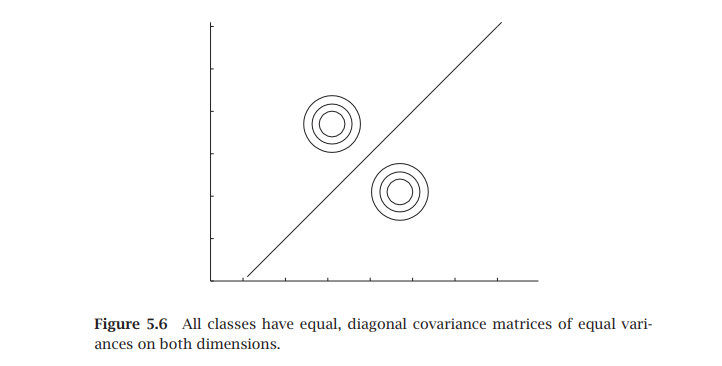

### ✏️ Öğrenci denemesi: En yakın ortalama

`m1=[2,3]`, `m2=[8,7]`, `x=[3,4]`. İki ortalamaya Öklid uzaklığını hesaplayın. Hangisi küçük?

In [25]:
# ✅ Öğretmen çözümü
def oklid_uzaklik(a,b):
    return math.sqrt(sum((a[i]-b[i])**2 for i in range(len(a))))

m1=[2,3]
m2=[8,7]
x=[3,4]
d1=oklid_uzaklik(x,m1)
d2=oklid_uzaklik(x,m2)
print(f"D1 = sqrt((3-2)^2 + (4-3)^2) = {d1:.4f}")
print(f"D2 = sqrt((3-8)^2 + (4-7)^2) = {d2:.4f}")
print("Sınıf:", "C1" if d1<d2 else "C2")

D1 = sqrt((3-2)^2 + (4-3)^2) = 1.4142
D2 = sqrt((3-8)^2 + (4-7)^2) = 5.8310
Sınıf: C1


## 4.6 Grafik: QDA ve LDA karar sınırlarını yan yana değil ayrı ayrı çizelim

Küçük bir koordinat ızgarasındaki her noktayı iki modelle sınıflandırıyoruz. Siyah çizgi, iki sınıf skorunun eşit olduğu **karar sınırı**dır.

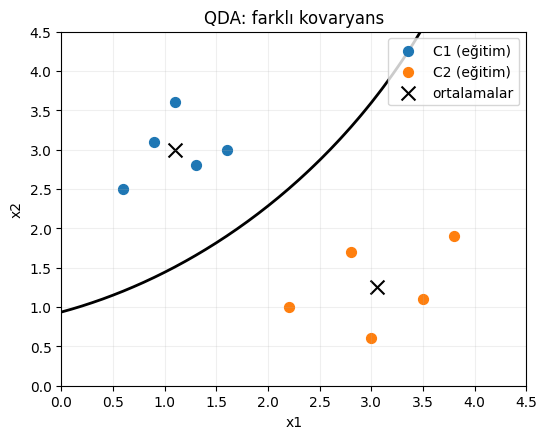

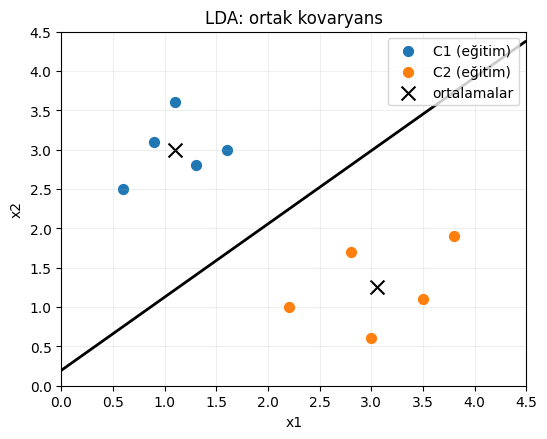

In [26]:
if GRAFIK_VAR:
    xs = [0 + i*0.1 for i in range(46)]
    ys = [0 + i*0.1 for i in range(46)]
    for model_adi, ortak_mi in [("QDA: farklı kovaryans",False), ("LDA: ortak kovaryans",True)]:
        fark_z = []
        for yy in ys:
            satir=[]
            for xx in xs:
                S1 = S_ortak if ortak_mi else S_C1
                S2 = S_ortak if ortak_mi else S_C2
                satir.append(sinif_skoru([xx,yy],m_C1,S1,0.5)-
                             sinif_skoru([xx,yy],m_C2,S2,0.5))
            fark_z.append(satir)
        plt.figure(figsize=(6,4.6))
        plt.contour(xs,ys,fark_z,levels=[0],colors=['black'],linewidths=2)
        plt.scatter([row[0] for row in C1_veri],[row[1] for row in C1_veri],label='C1 (eğitim)',s=50)
        plt.scatter([row[0] for row in C2_veri],[row[1] for row in C2_veri],label='C2 (eğitim)',s=50)
        plt.scatter([m_C1[0],m_C2[0]],[m_C1[1],m_C2[1]],marker='x',s=100,color='black',label='ortalamalar')
        plt.xlabel('x1'); plt.ylabel('x2'); plt.title(model_adi)
        plt.legend(); plt.grid(alpha=0.2); plt.show()
else:
    print('matplotlib kurulu değil, grafik atlandı.')

---
# 5. Model karmaşıklığı ve RDA — 10 dakika (5.6)

**💡 Anlat:** Çok serbest kovaryans matrisi ayrıntıları öğrenebilir ama çok parametre gerekir. Küçük veride fazla parametre hesaplamak hatalara duyarlılık oluşturur.

| Kovaryans modeli | Kovaryans parametre sayısı |
|---|---:|
| Ortak küresel (`s²I`) | 1 |
| Ortak köşegen | d |
| Ortak genel | d(d+1)/2 |
| K sınıf için ayrı genel | Kd(d+1)/2 |

Örneğin `K=3`, `d=10` ise son durum `3×10×11/2=165` kovaryans parametresine ihtiyaç duyar.

### Şekil 5.7 — Aynı veri, dört farklı kovaryans varsayımı

![Aynı veri, dört farklı kovaryans varsayımı](attachment:figure_Şekil 5_7.png)

**Grafik yorumu:** Grafiğin üstündeki anakütle dağılımından üretilen aynı veri üzerinde farklı kovaryans varsayımları **farklı karar sınırları** oluşturur. Serbest model daha esnek; ortak/köşegen/eşit varyans modelleri daha kısıtlıdır.

*Görsel: kullanıcı tarafından sağlanan Alpaydın (2014) kaynak şekli; açıklamalar eğitim amaçlıdır.*
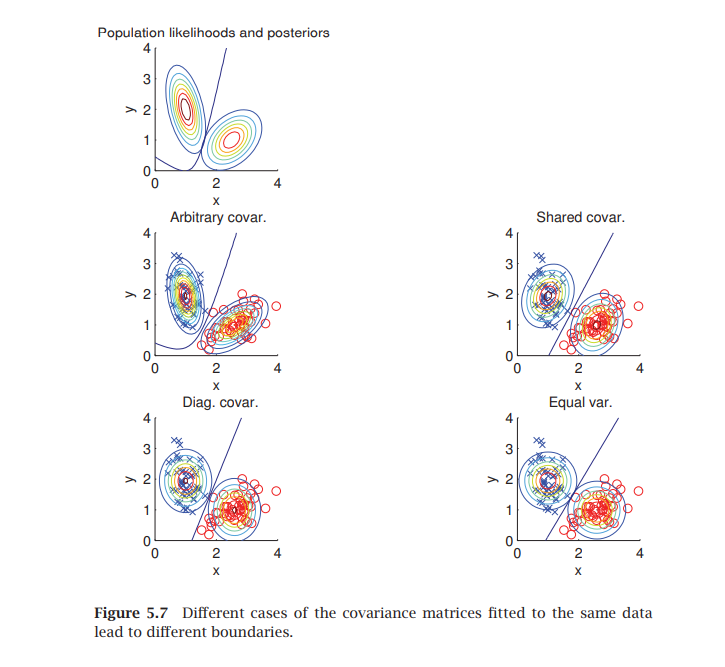

In [27]:
# Parametre sayıları nasıl büyüyor?
K = 3
d = 10
sayilar = {
    "Ortak küresel": 1,
    "Ortak köşegen": d,
    "Ortak genel": d*(d+1)//2,
    "Sınıfa ayrı genel (QDA)": K*d*(d+1)//2,
}
for model, n_param in sayilar.items():
    print(f"{model:28s}: {n_param:3d} kovaryans parametresi")
print("Ayrıca sınıf ortalamaları:", K*d, "parametre")

Ortak küresel               :   1 kovaryans parametresi
Ortak köşegen               :  10 kovaryans parametresi
Ortak genel                 :  55 kovaryans parametresi
Sınıfa ayrı genel (QDA)     : 165 kovaryans parametresi
Ayrıca sınıf ortalamaları: 30 parametre


## 5.1 RDA: Kovaryans matrislerini karıştıralım

\[
S_i'=\alpha s^2I+\beta S+(1-\alpha-\beta)S_i
\]

- `α=β=0` → QDA
- `α=0, β=1` → LDA
- `α=1, β=0` → eşit varyans / en yakın ortalama

**Teorik örnekteki sayılar:** `α=0.2`, `β=0.3`, `s²I=[[4,0],[0,4]]`, `S=[[5,1],[1,5]]`, `Sᵢ=[[4,2],[2,9]]`.

In [28]:
# Matris karışımı eleman eleman hesaplanabilir; numpy gerekmez.
def rda_kovaryans(alpha,beta,s2,S,S_i):
    if not (alpha >= 0 and beta >= 0 and alpha + beta <= 1):
        raise ValueError("α, β >= 0 ve α + β <= 1 olmalıdır.")
    I = [[1,0],[0,1]]
    return [[alpha*s2*I[i][j] + beta*S[i][j] + (1-alpha-beta)*S_i[i][j]
             for j in range(2)] for i in range(2)]

S_shared = [[5,1],[1,5]]
S_i = [[4,2],[2,9]]
S_yeni = rda_kovaryans(0.2,0.3,4,S_shared,S_i)
print("0.2×4I + 0.3×S + 0.5×S_i =")
for row in S_yeni:
    print([round(x,2) for x in row])
print("Beklenen: [[4.3, 1.3], [1.3, 6.8]]")

0.2×4I + 0.3×S + 0.5×S_i =
[4.3, 1.3]
[1.3, 6.8]
Beklenen: [[4.3, 1.3], [1.3, 6.8]]


### ✏️ Öğrenci denemesi

`α=0, β=1` yazınca neden sonuç `S_shared` oluyor? Kodu çalıştırın ve sonuçları karşılaştırın. Ardından `α=0, β=0` durumunu deneyin.

In [29]:
# ✅ Öğretmen çözümü
print("LDA (α=0,β=1):", rda_kovaryans(0,1,4,S_shared,S_i))
print("QDA (α=0,β=0):", rda_kovaryans(0,0,4,S_shared,S_i))

LDA (α=0,β=1): [[5, 1], [1, 5]]
QDA (α=0,β=0): [[4, 2], [2, 9]]


---
# 6. Ayrık özellikler ve Naive Bayes — 15 dakika (5.7)

**💡 Anlat:** Bütün özellikler yaş/gelir gibi sürekli sayı değildir. Bazıları **evet/hayır (0/1)**, bazıları **renk/kategori** değeridir. Bernoulli Naive Bayes 0/1 özellikleri işler.

\[
P(x\mid C_i)=\prod_{j=1}^{d} p_{ij}^{x_j}(1-p_{ij})^{1-x_j}
\]

Bir kelime varsa `x_j=1` → `p_ij`; yoksa `x_j=0` → `1-p_ij` çarpılır.

## 6.1 İki kelimeyle spam sınıflandırma

Teorideki aynı sayıları kullanalım. Özellikler:

- `x1=1`: "bedava" kelimesi var
- `x2=1`: "ödül" kelimesi var

| | Spam | Normal |
|---|---:|---:|
| `P(bedava=1|sınıf)` | 0.80 | 0.10 |
| `P(ödül=1|sınıf)` | 0.60 | 0.05 |
| Önsel `P(sınıf)` | 0.40 | 0.60 |

İki kelime de varsa (`x=[1,1]`), normalize edilmemiş sınıf skorları:

\[
Spam: 0.8\times0.6\times0.4=0.192
\]

\[
Normal: 0.1\times0.05\times0.6=0.003
\]

In [30]:
spam_prior = 0.4
normal_prior = 0.6
p_spam = [0.8,0.6]       # bedava, ödül
p_normal = [0.1,0.05]
yeni_mail = [1,1]

spam_skor = spam_prior*p_spam[0]*p_spam[1]
normal_skor = normal_prior*p_normal[0]*p_normal[1]
posterior_spam = spam_skor/(spam_skor+normal_skor)
print("Spam skoru: 0.4 × 0.8 × 0.6 =", spam_skor)
print("Normal skoru: 0.6 × 0.1 × 0.05 =", normal_skor)
print("P(Spam | x) =", round(posterior_spam,4))
print("Karar:", "SPAM" if spam_skor > normal_skor else "NORMAL")

Spam skoru: 0.4 × 0.8 × 0.6 = 0.19200000000000003
Normal skoru: 0.6 × 0.1 × 0.05 = 0.003
P(Spam | x) = 0.9846
Karar: SPAM


## 6.2 Kelimenin bulunmadığı durumda ne olacak?

Şimdi `x=[0,1]` olsun. "bedava" **yok**, "ödül" **var**. Bu durumda `P(bedava yok|Spam)=1-0.8=0.2` kullanılır. Genel fonksiyon yazalım.

In [31]:
def bernoulli_nb_olasilik(x, kelime_olasiliklari, onsel):
    skor = onsel
    for j, mevcut_mu in enumerate(x):
        p = kelime_olasiliklari[j]
        if mevcut_mu == 1:
            skor *= p
        else:
            skor *= (1-p)
    return skor

for mail in [[1,1],[0,1],[1,0],[0,0]]:
    s = bernoulli_nb_olasilik(mail,p_spam,spam_prior)
    n = bernoulli_nb_olasilik(mail,p_normal,normal_prior)
    karar = "SPAM" if s>n else "NORMAL"
    print(f"x={mail} | spam skoru={s:.5f}, normal skoru={n:.5f} => {karar}")

x=[1, 1] | spam skoru=0.19200, normal skoru=0.00300 => SPAM
x=[0, 1] | spam skoru=0.04800, normal skoru=0.02700 => SPAM
x=[1, 0] | spam skoru=0.12800, normal skoru=0.05700 => SPAM
x=[0, 0] | spam skoru=0.03200, normal skoru=0.51300 => NORMAL


### ✏️ Öğrenci denemesi

`x=[1,0]` için *spam skorunu* kağıtta bulun. Beklenen: `0.4 × 0.8 × (1-0.6) = 0.128`. Normal skoru ne olur? Hangi sınıf seçilir?

In [32]:
# ✅ Öğretmen çözümü
mail=[1,0]
s=bernoulli_nb_olasilik(mail,p_spam,spam_prior)
n=bernoulli_nb_olasilik(mail,p_normal,normal_prior)
print("Spam = 0.4×0.8×0.4 =",round(s,4))
print("Normal = 0.6×0.1×0.95 =",round(n,4))
print("Karar:", "SPAM" if s>n else "NORMAL")

Spam = 0.4×0.8×0.4 = 0.128
Normal = 0.6×0.1×0.95 = 0.057
Karar: SPAM


## 6.3 Çok kategorili özellik → One-Hot Encoding

Renk: `{Kırmızı, Mavi, Yeşil, Siyah}`. Her kategori için bir 0/1 sütunu oluştururuz:

- Kırmızı → `[1,0,0,0]`
- Mavi → `[0,1,0,0]`
- Yeşil → `[0,0,1,0]`
- Siyah → `[0,0,0,1]`

**Önemli:** Tek bir kategorik değişkenin one-hot sütunları birbirinden bağımsız değildir. Naive Bayes'in koşullu bağımsızlık varsayımı **farklı başlangıç özellikleri** içindir.

In [33]:
renk_sozlugu = ["Kırmızı", "Mavi", "Yeşil", "Siyah"]

def one_hot(renk):
    return [1 if secenek == renk else 0 for secenek in renk_sozlugu]

for renk in renk_sozlugu:
    print(f"{renk:8s} => {one_hot(renk)}")

Kırmızı  => [1, 0, 0, 0]
Mavi     => [0, 1, 0, 0]
Yeşil    => [0, 0, 1, 0]
Siyah    => [0, 0, 0, 1]


## 6.4 Bag of Words / kelime çantası

Belgedeki kelimelerin varlığı 0/1 ile gösterilir; sıralama korunmaz. Haber sınıflandırma gibi metin problemlerinde kullanılabilir.

In [34]:
kelimeler = ["futbol", "seçim", "ekonomi"]
dokumanlar = ["Futbol takımı kazandı", "Seçim ve ekonomi konuşuldu", "Futbol ekonomisi büyüyor"]

def metin_vektoru(metin, sozluk):
    # Basit sınıf örneği: küçük harfe çevirip kelimenin tam olarak bulunmasına bakar.
    kelime_kumesi = set(metin.lower().split())
    return [1 if kelime in kelime_kumesi else 0 for kelime in sozluk]

for cumle in dokumanlar:
    print(cumle, "=>", metin_vektoru(cumle,kelimeler))
print("Not: bu basit işlem ek/morfoloji analizi yapmaz; kelime eşleşmesi tamdır.")

Futbol takımı kazandı => [1, 0, 0]
Seçim ve ekonomi konuşuldu => [0, 1, 1]
Futbol ekonomisi büyüyor => [1, 0, 0]
Not: bu basit işlem ek/morfoloji analizi yapmaz; kelime eşleşmesi tamdır.


---
# 7. Çoklu doğrusal regresyon — 15 dakika (5.8)

**💡 Anlat:** Sınıflandırmada bir etiket seçiyorduk; regresyonda sayısal bir değer tahmin ediyoruz.

\[
\hat y = w_0+w_1x_1+w_2x_2+\cdots+w_dx_d
\]

`w₀` sabit terim (bias/intercept); `w₁, w₂,...` ağırlıklardır.

In [35]:
# Önceden verilmiş bir modelle tahmin yapalım.
# Not = 10 + 5*çalışma + 0.3*devam + 2*ödev
sabit = 10
calisma = 6
devam = 80
odev = 4
tahmin = sabit + 5*calisma + 0.3*devam + 2*odev
print("10 + 5×6 + 0.3×80 + 2×4 =",tahmin)

10 + 5×6 + 0.3×80 + 2×4 = 72.0


## 7.1 Hata kareleri, MSE ve kayıp fonksiyonu

Gerçek not 75, tahmin 72 ise hata `75-72=3`, hata karesi `3²=9`.

\[
MSE=\frac1N\sum_{t=1}^{N}(y_t-\hat y_t)^2
\]

Kitaptaki `E = 1/2 Σ(y-ŷ)²` aynı optimuma sahiptir: `E = N/2 × MSE`.

In [36]:
gercek = [75,60,90]
tahminler = [72,65,85]
hata_kareleri = []
for y, y_tahmin in zip(gercek,tahminler):
    fark = y-y_tahmin
    hata_kareleri.append(fark**2)
    print(f"Gerçek {y}, tahmin {y_tahmin}: hata={fark}, kare={fark**2}")
mse = sum(hata_kareleri)/len(hata_kareleri)
print("Hata kareleri toplamı:",sum(hata_kareleri))
print("MSE =",mse)

Gerçek 75, tahmin 72: hata=3, kare=9
Gerçek 60, tahmin 65: hata=-5, kare=25
Gerçek 90, tahmin 85: hata=5, kare=25
Hata kareleri toplamı: 59
MSE = 19.666666666666668


## 7.2 Normal denklemi elde etmek

Örnek veri:

| x1 | x2 | Gerçek y |
|---:|---:|---:|
| 0 | 0 | 1 |
| 1 | 0 | 3 |
| 0 | 1 | 4 |
| 1 | 1 | 6 |

Sabit terim için her satırın başına `1` koyuyoruz:

\[
X=\begin{bmatrix}1&0&0\\1&1&0\\1&0&1\\1&1&1\end{bmatrix},\quad
r=\begin{bmatrix}1\\3\\4\\6\end{bmatrix}
\]

Normal denklem:

\[
X^TXw=X^Tr
\]

Matrisin boyutları: `X(4×3)`, `Xᵀ(3×4)`, `XᵀX(3×3)`, `w(3×1)`, `r(4×1)`.

In [37]:
# Listelerle genel bir matris transpozu ve çarpımı yazalım.
def transpoz(A):
    return [list(sutun) for sutun in zip(*A)]


def matris_carp(A,B):
    if len(A[0]) != len(B):
        raise ValueError("Boyutlar çarpım için uyuşmuyor.")
    return [[sum(A[i][k]*B[k][j] for k in range(len(B)))
             for j in range(len(B[0]))] for i in range(len(A))]

X_reg = [[1,0,0],[1,1,0],[1,0,1],[1,1,1]]
y_reg = [[1],[3],[4],[6]]
XT = transpoz(X_reg)
XTX = matris_carp(XT,X_reg)
XTy = matris_carp(XT,y_reg)
print("X^T =",XT)
print("X^T X =")
for satir in XTX:
    print(satir)
print("X^T y =",XTy)

X^T = [[1, 1, 1, 1], [0, 1, 0, 1], [0, 0, 1, 1]]
X^T X =
[4, 2, 2]
[2, 2, 1]
[2, 1, 2]
X^T y = [[14], [9], [10]]


## 7.3 Sayıların nereden geldiğini gösterelim

\[
X^TX=\begin{bmatrix}4&2&2\\2&2&1\\2&1&2\end{bmatrix},\qquad
X^Ty=\begin{bmatrix}14\\9\\10\end{bmatrix}
\]

Örneğin `XᵀX` sol üst hücre: `1+1+1+1=4`; sağdaki sonuç vektörünün ikinci hücresi: `0×1+1×3+0×4+1×6=9`.

Böylece normal denklem üç adet denklem verir:

\[
\begin{aligned}
4w_0+2w_1+2w_2&=14\\
2w_0+2w_1+w_2&=9\\
2w_0+w_1+2w_2&=10
\end{aligned}
\]

İkinciyi 2 ile çarpıp birinciyi çıkarınca `2w₁=4` → `w₁=2`; üçüncüyü 2 ile çarpıp birinciyi çıkarınca `2w₂=6` → `w₂=3`. İlk denkleme koyunca `w₀=1`.

In [38]:
# Öğrenci kontrolü: Bulduğumuz ağırlıklar normal denklemi sağlıyor mu?
w_reg = [[1],[2],[3]]
sol = matris_carp(XTX,w_reg)
print("Sol taraf X^T X w =", sol)
print("Sağ taraf X^T y   =", XTy)
assert sol == XTy
print("Bütün denklemler sağlandı.")

Sol taraf X^T X w = [[14], [9], [10]]
Sağ taraf X^T y   = [[14], [9], [10]]
Bütün denklemler sağlandı.


## 7.4 Katsayıları otomatik hesaplamak: Gauss eleme yöntemi

**Öğretmen notu:** Bu hücre öğrenciler için ileri düzey olabilir. Süre kısaysa `7.3`'teki elle çözümü gösterip bu hücreyi **hazır yardımcı fonksiyon** olarak kullanın. `numpy` kullanmadan 3×3 lineer sistemi çözmektedir. Matematiksel fikir: satırlardan birbirini çıkartarak bilinmeyenleri tek tek ayırmak.

In [39]:
def lineer_sistem_coz(A,b):
    """Gauss-Jordan eleme; öğretici küçük, kare ve terslenebilir sistemler için."""
    n=len(A)
    # [A | b] genişletilmiş matrisi
    M = [[float(A[i][j]) for j in range(n)] + [float(b[i])] for i in range(n)]
    for pivot_sutunu in range(n):
        # En büyük mutlak pivotu seçerek sıfıra bölme riskini azaltalım.
        pivot_satiri = max(range(pivot_sutunu,n),key=lambda r:abs(M[r][pivot_sutunu]))
        M[pivot_sutunu],M[pivot_satiri] = M[pivot_satiri],M[pivot_sutunu]
        pivot = M[pivot_sutunu][pivot_sutunu]
        if abs(pivot)<1e-12:
            raise ValueError("Sistem tekil: benzersiz çözüm yok.")
        M[pivot_sutunu] = [deger/pivot for deger in M[pivot_sutunu]]
        for i in range(n):
            if i != pivot_sutunu:
                katsayi = M[i][pivot_sutunu]
                M[i] = [M[i][j] - katsayi*M[pivot_sutunu][j] for j in range(n+1)]
    return [M[i][-1] for i in range(n)]

cozum = lineer_sistem_coz(XTX,[satir[0] for satir in XTy])
print("[w0,w1,w2] =", [round(x,6) for x in cozum])
print("Beklenen: [1,2,3]")

[w0,w1,w2] = [1.0, 2.0, 3.0]
Beklenen: [1,2,3]


## 7.5 Modelin tahminleri ve MSE

\[
\hat y=1+2x_1+3x_2
\]

Dört eğitim gözleminin tahminlerini yapıp MSE'yi ölçelim. Bu **eğitim hatasıdır**; test başarısı hakkında tek başına garanti vermez.

In [40]:
def regresyon_tahmin(x1,x2,agirliklar):
    w0,w1,w2=agirliklar
    return w0+w1*x1+w2*x2

hata_kareleri=[]
for row,gercek_satir in zip(X_reg,y_reg):
    x1,x2=row[1],row[2]
    y_hat=regresyon_tahmin(x1,x2,cozum)
    y=gercek_satir[0]
    hata=(y-y_hat)**2
    hata_kareleri.append(hata)
    print(f"x=({x1},{x2}) | gerçek={y}, tahmin={y_hat:.2f}, hata²={hata:.2f}")
print("MSE =",sum(hata_kareleri)/len(hata_kareleri))

x=(0,0) | gerçek=1, tahmin=1.00, hata²=0.00
x=(1,0) | gerçek=3, tahmin=3.00, hata²=0.00
x=(0,1) | gerçek=4, tahmin=4.00, hata²=0.00
x=(1,1) | gerçek=6, tahmin=6.00, hata²=0.00
MSE = 0.0


### ✏️ Öğrenci denemesi: Yeni gözleme tahmin

Model `ŷ = 1 + 2x₁ + 3x₂`. `x₁=2`, `x₂=3` için tahmin kaçtır? Adım adım: `1 + (2×2) + (3×3) = ?`

In [41]:
# ✅ Öğretmen çözümü
son_tahmin = regresyon_tahmin(2,3,cozum)
print("1 + 2×2 + 3×3 =",son_tahmin)  # 14

1 + 2×2 + 3×3 = 14.0


## 7.6 İsteğe bağlı: Polinom/özellik dönüşümü

İstatistiksel model katsayılara göre hâlâ doğrusal olabilir, ancak girişe göre eğrisel davranabilir:

\[
\hat y = w_0+w_1x+w_2x^2
\]

Bu modelde `[1, x, x²]` özelliklerini hazırlıyoruz. Girişten türetilen yeni özelliklere **basis functions (taban fonksiyonları)** denir.

In [42]:
# x -> [1, x, x^2] dönüşümü
sayilar = [0,1,2,3]
for x in sayilar:
    ozellik_vektoru = [1,x,x*x]
    print(f"x={x} => [1, x, x²] = {ozellik_vektoru}")

x=0 => [1, x, x²] = [1, 0, 0]
x=1 => [1, x, x²] = [1, 1, 1]
x=2 => [1, x, x²] = [1, 2, 4]
x=3 => [1, x, x²] = [1, 3, 9]


---
# 8. Dersi kapatırken — hızlı tekrar

### 60 saniyelik sözlü yoklama

1. `N×d` matrisindeki `N` ve `d` nedir?
2. Varyans ve kovaryans arasındaki fark nedir?
3. Korelasyon sıfır olunca değişkenler kesin bağımsız mıdır?
4. Mahalanobis uzaklığı Öklid'den hangi yönüyle farklıdır?
5. QDA ve LDA'yı ayıran kovaryans varsayımı nedir?
6. Hangi varsayımda eş yoğunluk eğrileri daire olur?
7. Bernoulli Naive Bayes'te özellik 0 ise hangi olasılık kullanılır?
8. Regresyonda `w₀` ne işe yarar?
9. `XᵀXw=Xᵀy` denklemi ne için kullanılır?
10. Test setindeki bilgilerle eksik değer doldurma ortalaması hesaplanır mı?

**Öğretmen kısa cevapları:** (1) gözlem ve özellik sayısı, (2) tek değişken yayılımı / birlikte değişim, (3) hayır, (4) kovaryansı hesaba katar, (5) ayrı / ortak kovaryans, (6) ortak eşit varyans ve sıfır kovaryans, (7) `1-p`, (8) sabit terim, (9) en küçük kareler ağırlıklarını bulma, (10) hayır.

### İsteğe bağlı ev ödevi (dersten sonra)

- `kovaryans_matrisi()` fonksiyonunu 3 farklı özellikli bir veri kümesinde çalıştırın.
- QDA/LDA örneğine yeni bir `x` ekleyerek tahmini karşılaştırın.
- Spam örneğinde üçüncü bir kelime özelliği tanımlayın ve Bernoulli Naive Bayes skorunu güncelleyin.
- Regresyon veri kümesine yeni bir gözlem ekleyip katsayıların değişimini yorumlayın.

**Kaynak:** Ethem Alpaydın, *Introduction to Machine Learning*, 2014, Bölüm 5.1–5.8. Sayısal örnekler bölümle eşleştirilmiş, bazı uygulama verileri laboratuvar için üretilmiştir. Gönderilen tüm orijinal görseller notebook içine gömülmüştür.